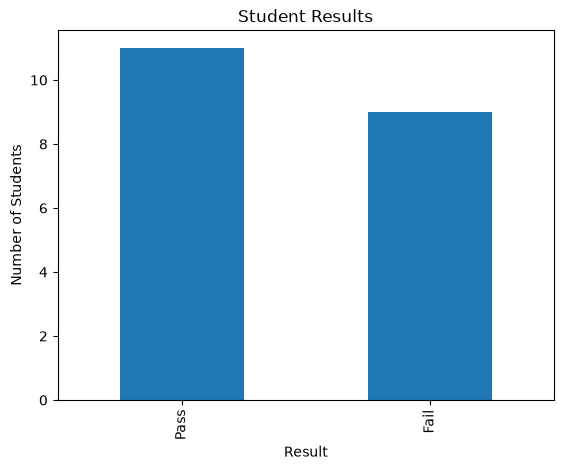

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/students.csv")

df["result"].value_counts().plot(kind="bar")
plt.title("Student Results")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.show()


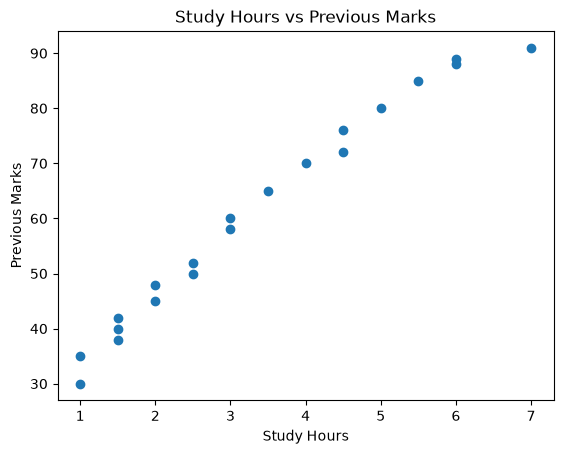

In [3]:
plt.scatter(df["study_hours"], df["previous_marks"])

plt.title("Study Hours vs Previous Marks")
plt.xlabel("Study Hours")
plt.ylabel("Previous Marks")
plt.show()

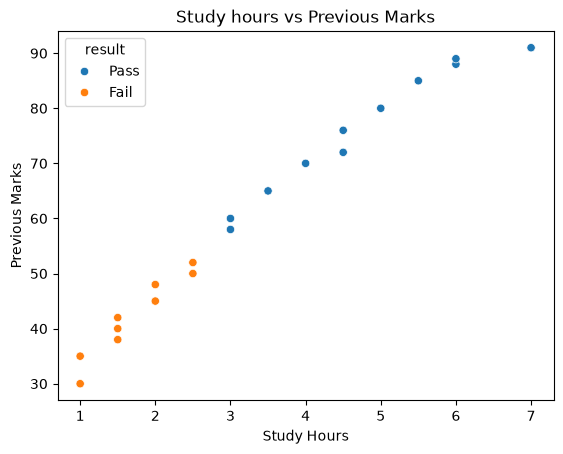

In [4]:
sns.scatterplot(data = df, x = "study_hours", y = "previous_marks", hue = "result")

plt.title("Study hours vs Previous Marks")
plt.xlabel("Study Hours")
plt.ylabel("Previous Marks")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop("result", axis=1)
y = df["result"]

y = y.map({"Pass": 1, "Fail": 0})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)


print(y.head())

(16, 5)
(4, 5)
(16,)
(4,)
0    1
1    0
2    1
3    0
4    1
Name: result, dtype: int64


In [6]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression();

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(y_pred)
print(y_test.values)

[1 0 0 0]
[1 0 0 0]


In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred);
precision = precision_score(y_test, y_pred);
recall = recall_score(y_test, y_pred);
f1 = f1_score(y_test, y_pred);

print("Accuracy: ", accuracy);
print("Precision: ", precision);
print("Recall: ", recall);
print("F1 Score: ", f1);

Accuracy:  1.0
Precision:  1.0
Recall:  1.0
F1 Score:  1.0


In [8]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred);

print(cm)

[[3 0]
 [0 1]]


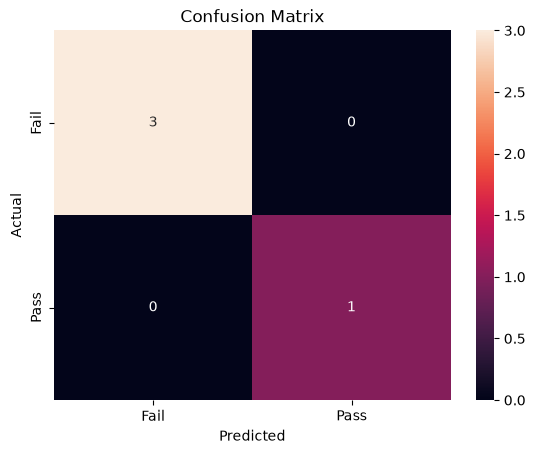

In [9]:
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [10]:
new_student = [[82, 4.5, 75, 80, 78]]

prediction = model.predict(new_student)

if prediction[0] == 1:
    print("Prediction: Pass")
else:
    print("Prediction: Fail")

Prediction: Pass


e:\VelnexxaProjects\Project 1 Student Performance Prediction System\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [11]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier();

tree_model.fit(X_train, y_train);

tree_pred = tree_model.predict(X_test);

tree_accuracy = accuracy_score(y_test, tree_pred);
tree_precision = precision_score(y_test, tree_pred);
tree_recall = recall_score(y_test, tree_pred);
tree_f1 = f1_score(y_test, tree_pred);

print(tree_pred);
print(y_test.values);

print("Decision Tree Model Performance:")
print("Accuracy: ", tree_accuracy);
print("Precision: ", tree_precision);
print("Recall: ", tree_recall);
print("F1-Score: ", tree_f1);

[1 0 0 0]
[1 0 0 0]
Decision Tree Model Performance:
Accuracy:  1.0
Precision:  1.0
Recall:  1.0
F1-Score:  1.0


In [12]:
from sklearn.ensemble import RandomForestClassifier

forest_model = RandomForestClassifier(n_estimators=100, random_state=42);

forest_model.fit(X_train, y_train);

forest_pred = forest_model.predict(X_test);

print(forest_pred);
print(y_test.values);

forest_accuracy = accuracy_score(y_test, forest_pred)
forest_precision = precision_score(y_test, forest_pred)
forest_recall = recall_score(y_test, forest_pred)
forest_f1 = f1_score(y_test, forest_pred)

print("Random Forest Model Performance:")
print("Accuracy: ", forest_accuracy)
print("Precision: ", forest_precision)
print("Recall: ", forest_recall)
print("F1-Score: ", forest_f1)

[1 0 0 0]
[1 0 0 0]
Random Forest Model Performance:
Accuracy:  1.0
Precision:  1.0
Recall:  1.0
F1-Score:  1.0


In [32]:
np.random.seed(42)

n = 100

attendance = np.random.randint(45, 96, n)
study_hours = np.round(np.random.uniform(1, 8, n), 1)
previous_marks = np.random.randint(30, 96, n)
assignment_score = np.random.randint(40, 96, n)
internal_marks = np.random.randint(35, 96, n)

study_score = (study_hours / 8) * 100

new_df = pd.DataFrame({
    "attendance": attendance,
    "study_hours": study_hours,
    "previous_marks": previous_marks,
    "assignment_score": assignment_score,
    "internal_marks": internal_marks
})

score = (
    attendance * 0.20 +
    study_hours * 0.15 +
    previous_marks * 0.30 +
    assignment_score * 0.15 +
    internal_marks * 0.20
)

print(score.min())
print(score.max())
print(score.mean())

new_df["result"] = np.where(score >= 55, "Pass", "Fail")

print(new_df.head())
print(new_df.shape)
print(new_df["result"].value_counts())

new_df.to_csv("../data/students_large.csv", index = False)

35.135000000000005
73.39
56.57295
   attendance  study_hours  previous_marks  assignment_score  internal_marks  \
0          83          1.1              32                81              50   
1          73          4.0              49                41              95   
2          59          3.8              88                65              73   
3          87          3.1              65                56              39   
4          52          1.1              48                79              56   

  result  
0   Fail  
1   Pass  
2   Pass  
3   Fail  
4   Fail  
(100, 6)
result
Pass    56
Fail    44
Name: count, dtype: int64


In [33]:
df = pd.read_csv("../data/students_large.csv")

X = df.drop("result", axis = 1)
y = df["result"]

y = y.map({"Pass": 1, "Fail": 0})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y, 
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

print(X_train.shape)
print(X_test.shape)

print(y_train.value_counts())
print(y_test.value_counts())

(80, 5)
(20, 5)
result
1    45
0    35
Name: count, dtype: int64
result
1    11
0     9
Name: count, dtype: int64


In [34]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(y_pred)
print(y_test.values)

[1 1 1 1 0 0 0 1 1 0 0 1 0 1 0 1 1 0 1 1]
[1 1 1 1 0 0 0 1 0 0 0 1 0 1 0 1 1 0 1 1]


In [35]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy: ", accuracy*100, "%")
print("Precision: ", precision*100, "%")
print("Recall: ", recall*100, "%")
print("F1-Score: ", f1*100, "%")

Accuracy:  95.0 %
Precision:  91.66666666666666 %
Recall:  100.0 %
F1-Score:  95.65217391304348 %


In [36]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 8  1]
 [ 0 11]]


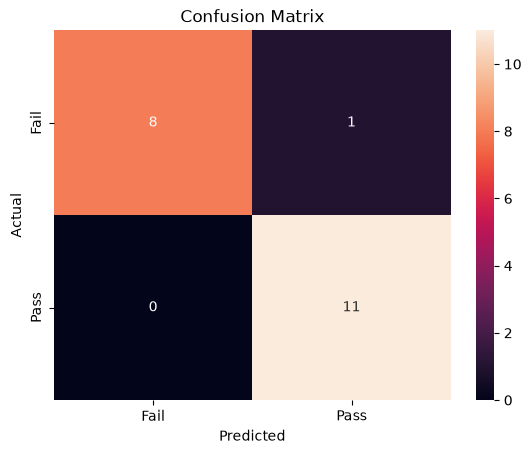

In [37]:
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [38]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier()

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

tree_accuracy = accuracy_score(y_test, tree_pred)
tree_precision = precision_score(y_test, tree_pred) 
tree_recall = recall_score(y_test, tree_pred)
tree_f1 = f1_score(y_test, tree_pred)

print("Decision Tree Model Performance:")
print("Accuracy: ", tree_accuracy*100, "%")
print("Precision: ", tree_precision*100, "%")
print("Recall: ", tree_recall*100, "%")
print("F1-Score: ", tree_f1*100, "%")

Decision Tree Model Performance:
Accuracy:  65.0 %
Precision:  70.0 %
Recall:  63.63636363636363 %
F1-Score:  66.66666666666666 %


[[6 3]
 [4 7]]


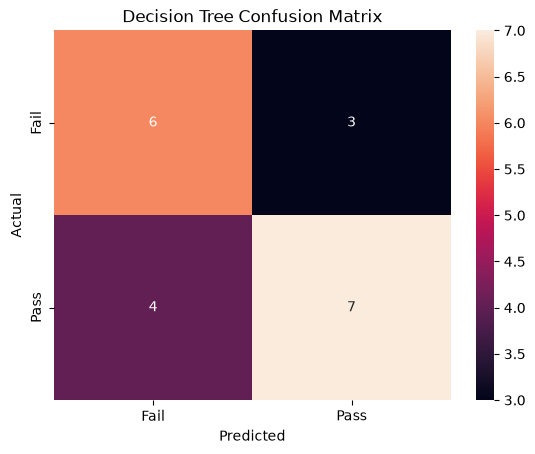

In [39]:
tree_cm = confusion_matrix(y_test, tree_pred)

print(tree_cm)

sns.heatmap(
    tree_cm,
    annot=True,
    fmt="d",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

In [40]:
from sklearn.ensemble import RandomForestClassifier

forest_model = RandomForestClassifier(n_estimators=100, random_state=42)

forest_model.fit(X_train, y_train)

forest_pred = forest_model.predict(X_test)

print(forest_pred)
print(y_test.values)

forest_accuracy = accuracy_score(y_test, forest_pred)
forest_precision = precision_score(y_test, forest_pred) 
forest_recall = recall_score(y_test, forest_pred)
forest_f1 = f1_score(y_test, forest_pred)

print("Random Forest Model Performance:")
print("Accuracy: ", forest_accuracy*100, "%")
print("Precision: ", forest_precision*100, "%")
print("Recall: ", forest_recall*100, "%")
print("F1-Score: ", forest_f1*100, "%")

[1 1 1 1 1 0 0 1 1 0 0 1 0 0 0 1 1 0 0 0]
[1 1 1 1 0 0 0 1 0 0 0 1 0 1 0 1 1 0 1 1]
Random Forest Model Performance:
Accuracy:  75.0 %
Precision:  80.0 %
Recall:  72.72727272727273 %
F1-Score:  76.19047619047619 %


In [41]:
for feature, coefficient in zip(X.columns, model.coef_[0]):
    print(feature, ":", coefficient)


id="4o9y8c"
print(X.describe().loc[["min", "max"]])

attendance : 0.6780397031100285
study_hours : 1.0148483925325111
previous_marks : 1.0813298550772696
assignment_score : 0.5143448593962705
internal_marks : 0.7510411429929675
     attendance  study_hours  previous_marks  assignment_score  internal_marks
min        45.0          1.0            30.0              40.0            35.0
max        95.0          8.0            95.0              95.0            95.0


In [42]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)    

print(X_train_scaled[:5])

[[ 0.03329955 -0.14286351 -1.74813579  1.24402457 -0.43809225]
 [-0.37654106  0.28439185  1.64630264 -1.12265632 -0.95518474]
 [-1.33283583  0.60483336  1.42000674 -1.5474452  -0.26572809]
 [-0.23992753  0.17757801  1.0805629  -0.45513094  0.02154552]
 [-0.23992753  0.4446126  -0.05091658  1.42607694 -0.95518474]]


In [44]:
scaled_model = LogisticRegression()

scaled_model.fit(X_train_scaled, y_train)

scaled_pred = scaled_model.predict(X_test_scaled)

print(scaled_pred)

scaled_accuracy = accuracy_score(y_test, scaled_pred)
scaled_precision = precision_score(y_test, scaled_pred)
scaled_recall = recall_score(y_test, scaled_pred)
scaled_f1 = f1_score(y_test, scaled_pred)

print("Scaled Logistic Regression Model Performance:")
print("Accuracy: ", scaled_accuracy*100, "%")
print("Precision: ", scaled_precision*100, "%")
print("Recall: ", scaled_recall*100, "%")
print("F1-Score: ", scaled_f1*100, "%")

[1 1 1 1 0 0 0 1 0 0 0 1 0 1 0 1 1 0 1 1]
Scaled Logistic Regression Model Performance:
Accuracy:  100.0 %
Precision:  100.0 %
Recall:  100.0 %
F1-Score:  100.0 %


In [45]:
for feature, coefficient in zip(X.columns, scaled_model.coef_[0]):
    print(feature, ":", coefficient)

attendance : 1.3651496256183029
study_hours : 0.5530726819972416
previous_marks : 2.2550323849694305
assignment_score : 0.7651995141849857
internal_marks : 1.6586384984193172


In [46]:
new_student = [[82, 4.5, 75, 80, 78]]

new_student_scaled = scaler.transform(new_student)

prediction = scaled_model.predict(new_student_scaled)

if prediction[0] == 1:
    print("Prediction: Pass")
else:
    print("Prediction: Fail")

Prediction: Pass


e:\VelnexxaProjects\Project 1 Student Performance Prediction System\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
